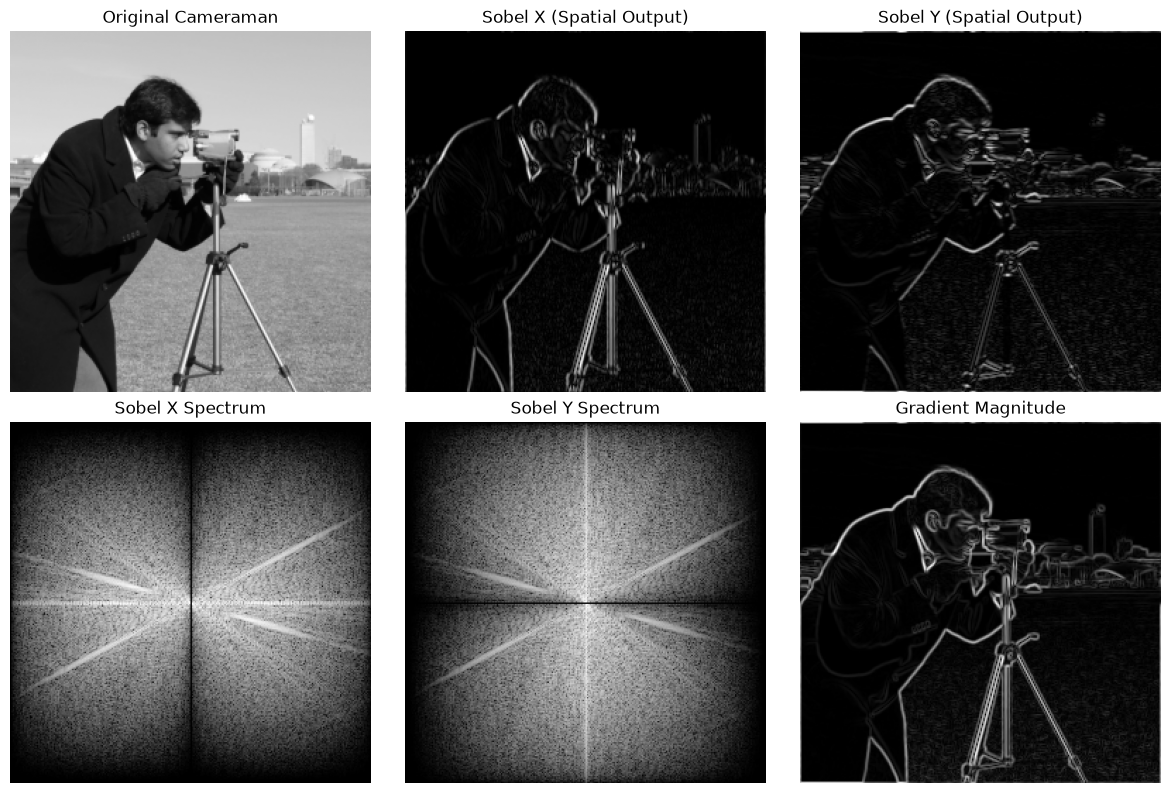

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
from numpy.fft import fft2, ifft2, ifftshift, fftshift

# Load and resize Cameraman image
image = resize(data.camera(), (256, 256), anti_aliasing=True)

# Sobel filters
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

# Pad and center the kernel, then compute its FFT
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    cy, cx = shape[0] // 2, shape[1] // 2

    padded[
        cy - kh // 2:cy - kh // 2 + kh,
        cx - kw // 2:cx - kw // 2 + kw
    ] = kernel

    return fft2(ifftshift(padded))

# FFT of image and Sobel filters
F = fft2(image)
Hx = center_embed_kernel(sobel_x, image.shape)
Hy = center_embed_kernel(sobel_y, image.shape)

# Multiply in the frequency domain
Fx = F * Hx
Fy = F * Hy

# Inverse FFT
gx = ifft2(Fx).real
gy = ifft2(Fy).real

# Combined edge magnitude
magnitude = np.hypot(gx, gy)

# Plot results
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

results = [
    image,
    np.abs(gx),
    np.abs(gy),
    np.log1p(np.abs(fftshift(Fx))),
    np.log1p(np.abs(fftshift(Fy))),
    magnitude
]

titles = [
    "Original Cameraman",
    "Sobel X (Spatial Output)",
    "Sobel Y (Spatial Output)",
    "Sobel X Spectrum",
    "Sobel Y Spectrum",
    "Gradient Magnitude"
]

for ax, result, title in zip(axes.flat, results, titles):
    ax.imshow(result, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()